<a id="1"></a>
<div style="padding:20px;
            color:white;
            margin:10;
            font-size:200%;
            text-align:left;
            display:fill;
            border-radius:5px;
            background-color:#294B8E;
            overflow:hidden;
            font-weight:700">If you like this work, please upvote this kernel  and share the kernel with others so we can all benefit</div>

https://www.linkedin.com/in/krishnaraj-palaniselvaraj/

https://www.kaggle.com/krishnaraj30

## <b><div style='padding:15px;background-color:#3aca5e;color:white;border-radius:2px;font-size:110%;text-align: center'>  Importing  Libraries</div></b>

This project centers on conducting Exploratory Data Analysis and predictive modeling using the Finance Loan Approval Prediction dataset. The methodological workflow encompasses comprehensive data cleaning—addressing missing values through median and mode imputation strategies—and the generation of insightful visualizations to dissect the relationships between various features. Ultimately, predictive algorithms, including Logistic Regression and Random Forest, were applied, demonstrating an accuracy of approximately 78.86% in anticipating loan approval statuses.

In [1]:

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt

In [2]:
df_train = pd.read_csv("/kaggle/input/finance-loan-approval-prediction-data/train.csv")
df_test = pd.read_csv("/kaggle/input/finance-loan-approval-prediction-data/test.csv")

In [3]:
df_train.head()


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [4]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [5]:
df_train.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [6]:
df_train['LoanAmount'].fillna(df_train['LoanAmount'].median(), inplace=True)

In [7]:
df_train.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount            0
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [8]:
df_train['Loan_Amount_Term'].fillna(df_train['Loan_Amount_Term'].median(), inplace=True)

In [9]:
df_train.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount            0
Loan_Amount_Term      0
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [10]:
df_train['Credit_History'].fillna(df_train['Credit_History'].median(), inplace=True)

In [11]:
df_train.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount            0
Loan_Amount_Term      0
Credit_History        0
Property_Area         0
Loan_Status           0
dtype: int64

In [12]:
df_train['Gender'].fillna(df_train['Gender'].mode()[0], inplace=True)

In [13]:
df_train.isnull().sum()

Loan_ID               0
Gender                0
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount            0
Loan_Amount_Term      0
Credit_History        0
Property_Area         0
Loan_Status           0
dtype: int64

In [14]:
df_train['Married'].fillna(df_train['Married'].mode()[0], inplace=True)

In [15]:
df_train.isnull().sum()

Loan_ID               0
Gender                0
Married               0
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount            0
Loan_Amount_Term      0
Credit_History        0
Property_Area         0
Loan_Status           0
dtype: int64

In [16]:
df_train['Dependents'].fillna(df_train['Dependents'].mode()[0], inplace=True)

In [17]:
df_train.isnull().sum()

Loan_ID               0
Gender                0
Married               0
Dependents            0
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount            0
Loan_Amount_Term      0
Credit_History        0
Property_Area         0
Loan_Status           0
dtype: int64

In [18]:
df_train['Self_Employed'].fillna(df_train['Self_Employed'].mode()[0], inplace=True)

In [19]:
df_train.isnull().sum()

Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64

<Axes: >

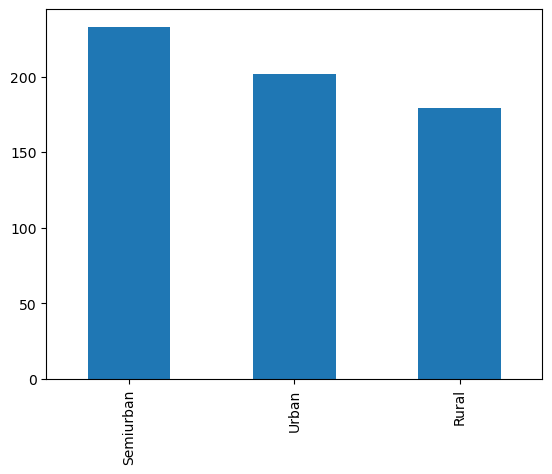

In [20]:
df_train["Property_Area"].value_counts().plot(kind="bar")

<Axes: >

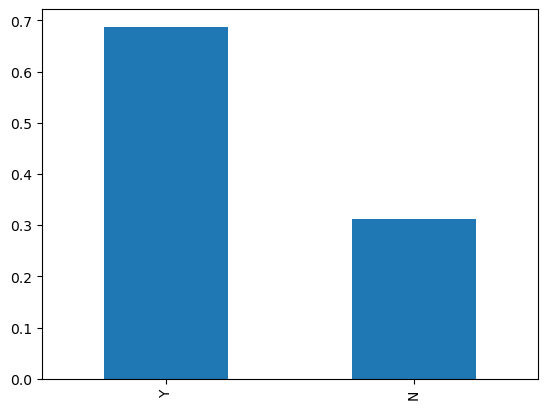

In [21]:
df_train["Loan_Status"].value_counts(normalize=True).plot(kind="bar")

<Axes: xlabel='Credit_History'>

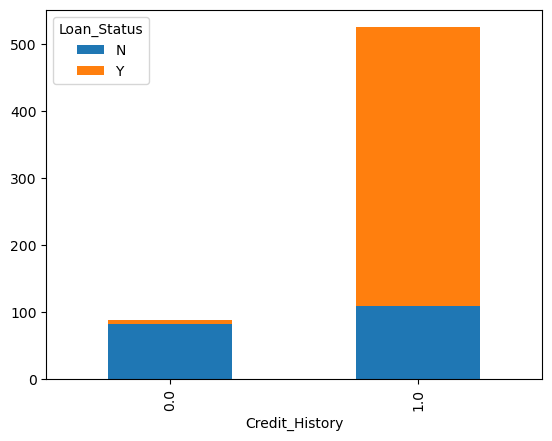

In [22]:
pd.crosstab(df_train['Credit_History'], df_train['Loan_Status']).plot(kind='bar', stacked=True)

<Axes: xlabel='Education'>

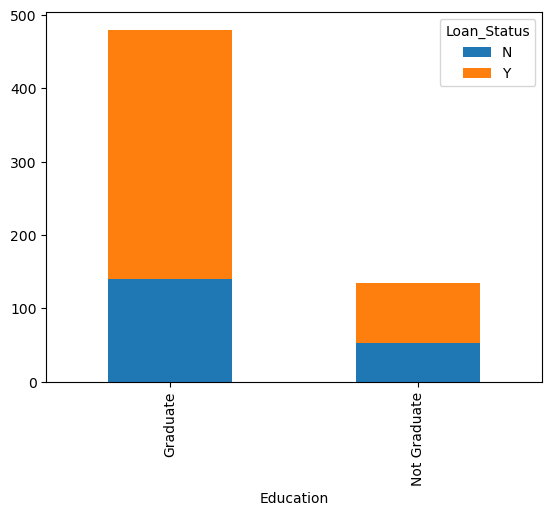

In [23]:
pd.crosstab(df_train['Education'], df_train['Loan_Status']).plot(kind='bar', stacked=True)

<Axes: >

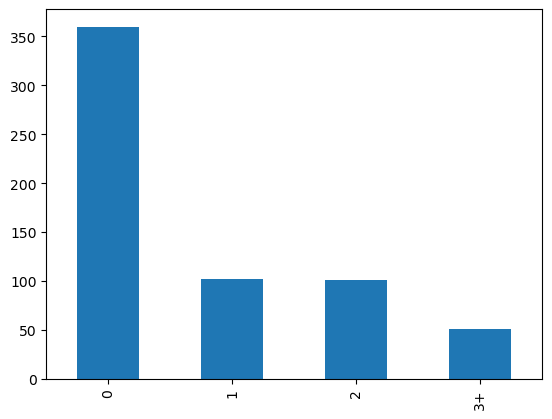

In [24]:
df_train["Dependents"].value_counts().plot(kind="bar")

<Axes: >

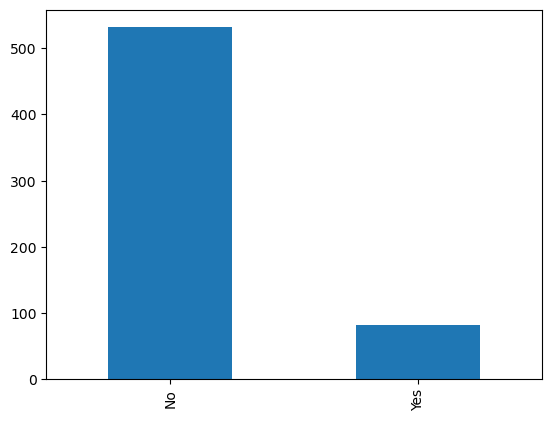

In [25]:
df_train["Self_Employed"].value_counts().plot(kind="bar")

<Axes: >

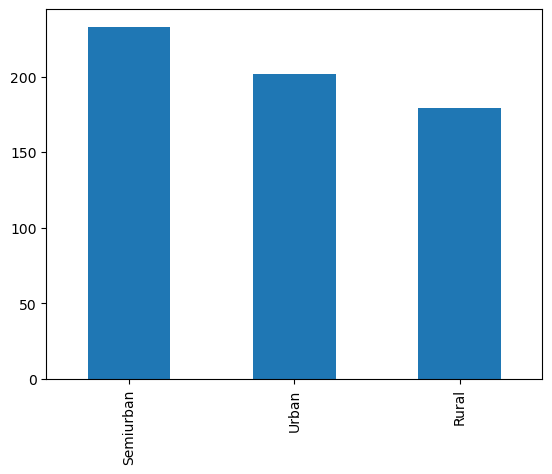

In [26]:
df_train["Property_Area"].value_counts().plot(kind="bar")

<Axes: >

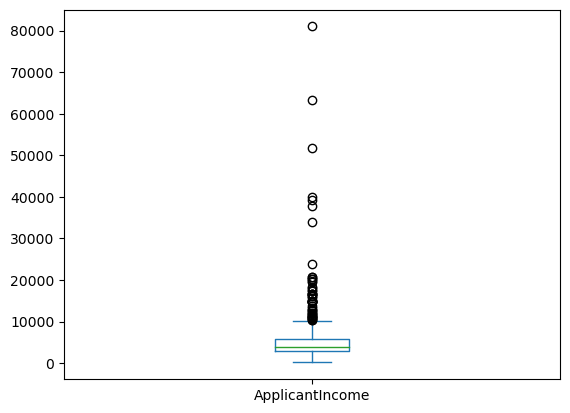

In [27]:
df_train['ApplicantIncome'].plot(kind='box')

In [28]:
import seaborn as sns

<Axes: xlabel='Loan_Status', ylabel='ApplicantIncome'>

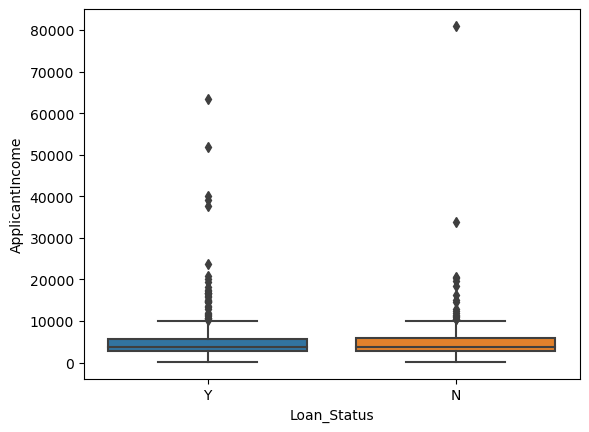

In [29]:
sns.boxplot(x='Loan_Status', y='ApplicantIncome', data=df_train)

<Axes: xlabel='Loan_Status', ylabel='CoapplicantIncome'>

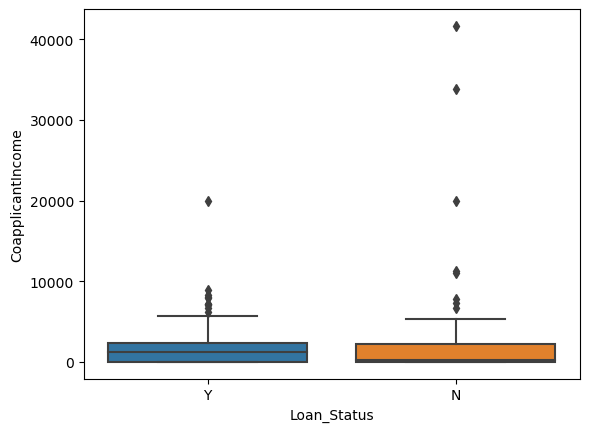

In [30]:
sns.boxplot(x='Loan_Status', y='CoapplicantIncome', data=df_train)

<Axes: >

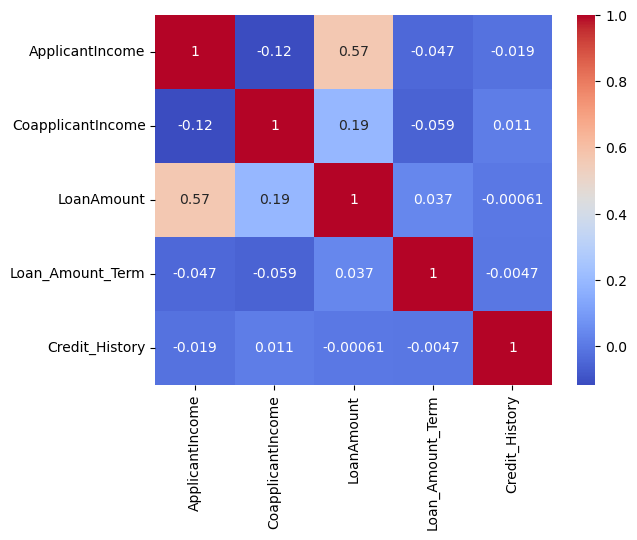

In [31]:
sns.heatmap(df_train.corr(numeric_only=True), annot=True, cmap="coolwarm")

In [32]:
import pandas as pd

df_train = pd.read_csv(
    "/kaggle/input/finance-loan-approval-prediction-data/train.csv"
)

In [33]:
df_train = pd.get_dummies(df_train, drop_first=True)

In [34]:
import pandas as pd
df_train = pd.read_csv('/kaggle/input/finance-loan-approval-prediction-data/train.csv')

In [35]:
df_train = pd.read_csv('/kaggle/input/finance-loan-approval-prediction-data/train.csv')

In [36]:
r = 10 / (12 * 100)
n = df_train["Loan_Amount_Term"]
P = df_train["LoanAmount"] * 1000

df_train["EMI"] = (P * r * (1 + r) ** n) / ((1 + r) ** n - 1)

In [37]:
df_train.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,EMI
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y,NaN
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N,1123.291610
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y,579.197236
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y,1053.085884
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y,1237.375914


In [38]:
import pandas as pd

df_train = pd.read_csv('/kaggle/input/finance-loan-approval-prediction-data/train.csv')

df_train['LoanAmount'].fillna(df_train['LoanAmount'].median(), inplace=True)
df_train['Loan_Amount_Term'].fillna(df_train['Loan_Amount_Term'].median(), inplace=True)
df_train['Credit_History'].fillna(df_train['Credit_History'].median(), inplace=True)
df_train['Gender'].fillna(df_train['Gender'].mode()[0], inplace=True)
df_train['Married'].fillna(df_train['Married'].mode()[0], inplace=True)
df_train['Dependents'].fillna(df_train['Dependents'].mode()[0], inplace=True)
df_train['Self_Employed'].fillna(df_train['Self_Employed'].mode()[0], inplace=True)

df_train = pd.get_dummies(df_train, drop_first=True)

In [39]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

X = df_train.drop('Loan_Status_Y', axis=1)
y = df_train['Loan_Status_Y']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LogisticRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, predictions))

Accuracy: 0.7886178861788617


In [40]:
from sklearn.ensemble import RandomForestClassifier

model_rf = RandomForestClassifier(random_state=42)
model_rf.fit(X_train, y_train)

predictions_rf = model_rf.predict(X_test)
print("Random Forest Accuracy:", accuracy_score(y_test, predictions_rf))

Random Forest Accuracy: 0.7886178861788617


In [41]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

models = {
    "Logistic Regression": LogisticRegression(),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42)
}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    print(f"{name} Accuracy: {accuracy_score(y_test, predictions)}")

Logistic Regression Accuracy: 0.7886178861788617
Random Forest Accuracy: 0.7886178861788617
Decision Tree Accuracy: 0.6829268292682927


In [42]:
df_train = pd.read_csv('/kaggle/input/finance-loan-approval-prediction-data/train.csv')

In [43]:
df_train['LoanAmount'].fillna(df_train['LoanAmount'].median(), inplace=True)
df_train['Loan_Amount_Term'].fillna(df_train['Loan_Amount_Term'].median(), inplace=True)
df_train['Credit_History'].fillna(df_train['Credit_History'].median(), inplace=True)
df_train['Gender'].fillna(df_train['Gender'].mode()[0], inplace=True)
df_train['Married'].fillna(df_train['Married'].mode()[0], inplace=True)
df_train['Dependents'].fillna(df_train['Dependents'].mode()[0], inplace=True)
df_train['Self_Employed'].fillna(df_train['Self_Employed'].mode()[0], inplace=True)

In [44]:
df_train['TotalIncome'] = df_train['ApplicantIncome'] + df_train['CoapplicantIncome']

In [45]:
df_train = pd.get_dummies(df_train, drop_first=True)

In [46]:
X = df_train.drop('Loan_Status_Y', axis=1)
y = df_train['Loan_Status_Y']

In [47]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

<a id="1"></a>
<div style="padding:20px;
            color:white;
            margin:10;
            font-size:200%;
            text-align:left;
            display:fill;
            border-radius:5px;
            background-color:#294B8E;
            overflow:hidden;
            font-weight:700">Demographical exploration</div>

<a id="1"></a>
<div style="padding:20px;
            color:white;
            margin:10;
            font-size:200%;
            text-align:left;
            display:fill;
            border-radius:5px;
            background-color:#294B8E;
            overflow:hidden;
            font-weight:700">Thank you All, I will appreciate you to check and share feedback on my other notebooks in your free time</div>



https://www.kaggle.com/code/krishnaraj30/visualization-decision-tree-classification

https://www.kaggle.com/code/krishnaraj30/decision-tree-sklearn-hyper-parameter-tuning

https://www.kaggle.com/code/krishnaraj30/house-price-explore-with-python-visualization

https://www.kaggle.com/code/krishnaraj30/clustering-segmentation-k-means

https://www.kaggle.com/code/krishnaraj30/exploratory-data-analysis-matplotlib-seaborn